# Validating the FP-Growth Route Rules

Goal: check that the association rules from `06_fp_routes.ipynb` (issue #13) describe lasting travel patterns, as Piazza Requirement 4 asks for a train/test split with suitable metrics.

Rules have no labels to score, so we use a **time hold-out**, run on Managed Apache Spark by `src/models/fpgrowth_validate.py` (batch `hshah82-fpgrowth-validate-1123`):

- **Train:** FP-Growth on a 10% sample of 2023–2024 trips, with the same baskets (`from=`, `to=`, `time=`, `day=`, `dist=`) and thresholds (minimum support 0.2%, minimum confidence 10%) as the M2 run.
- **Test:** a 10% sample of Jan 2025 – Aug 2026 trips. For every training rule "if A then C", the job counts A, C and A + C in the test baskets and recomputes support, confidence and lift.
- **A rule holds** if its test confidence is still at least 10% and its test lift is still above 1 (the items still go together more often than by chance).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RES = ROOT / "results" / "fpgrowth_validation"
FIGS = ROOT / "docs" / "figures"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9aa5b1"

summary = pd.read_csv(RES / "holdout_summary.csv")
rules = pd.read_csv(RES / "rules_holdout.csv")
summary.T.round(4)

,0
train_baskets,1.425864e+07
test_baskets,1.237630e+07
rules,4.217000e+03
rules_hold,3.026000e+03
share_hold,7.176000e-01
still_frequent,4.102000e+03
mean_abs_conf_change,6.800000e-03
corr_confidence,9.990000e-01
corr_log_lift,9.988000e-01


## Do confidence and lift stay the same on new data?

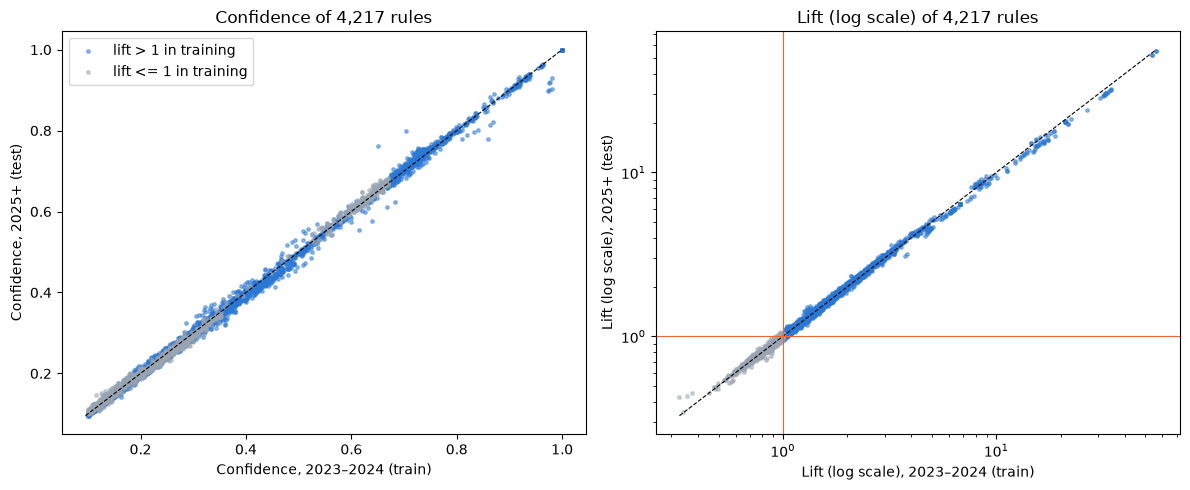

rules: 4,217   hold: 3,026 (71.8%)   still frequent: 4,102
mean |confidence change| 0.0068   corr(confidence) 0.999   corr(log lift) 0.999


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
pos = rules["train_lift"] > 1
for ax, col, title, log in [(axes[0], "confidence", "Confidence", False), (axes[1], "lift", "Lift (log scale)", True)]:
    ax.scatter(rules.loc[pos, f"train_{col}"], rules.loc[pos, f"test_{col}"], s=6, alpha=0.5, color=BLUE,
               label="lift > 1 in training")
    ax.scatter(rules.loc[~pos, f"train_{col}"], rules.loc[~pos, f"test_{col}"], s=6, alpha=0.5, color=GREY,
               label="lift <= 1 in training")
    lo = min(rules[f"train_{col}"].min(), rules[f"test_{col}"].min())
    hi = max(rules[f"train_{col}"].max(), rules[f"test_{col}"].max())
    ax.plot([lo, hi], [lo, hi], color="black", lw=0.8, ls="--")
    if log:
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.axhline(1, color=ORANGE, lw=0.8); ax.axvline(1, color=ORANGE, lw=0.8)
    ax.set_xlabel(f"{title}, 2023–2024 (train)")
    ax.set_ylabel(f"{title}, 2025+ (test)")
    ax.set_title(f"{title} of {len(rules):,} rules")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIGS / "fp_holdout_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

s = summary.iloc[0]
print(f"rules: {s.rules:,.0f}   hold: {s.rules_hold:,.0f} ({100 * s.share_hold:.1f}%)   still frequent: {s.still_frequent:,.0f}")
print(f"mean |confidence change| {s.mean_abs_conf_change:.4f}   corr(confidence) {s.corr_confidence:.3f}   corr(log lift) {s.corr_log_lift:.3f}")

Almost every rule sits on the diagonal: confidence changes by 0.007 on average (0.7 percentage points) and both confidence and log lift correlate at 0.999 between the two periods. The grey points are rules whose lift was already 1 or below in training; they stay below 1 in the test period too.

## Which rules fail, and why?

rules that fail: 1,191
  test confidence below 10%: 20
  test lift 1 or below: 1172  (of these, lift was already <= 1 in training: 1149)


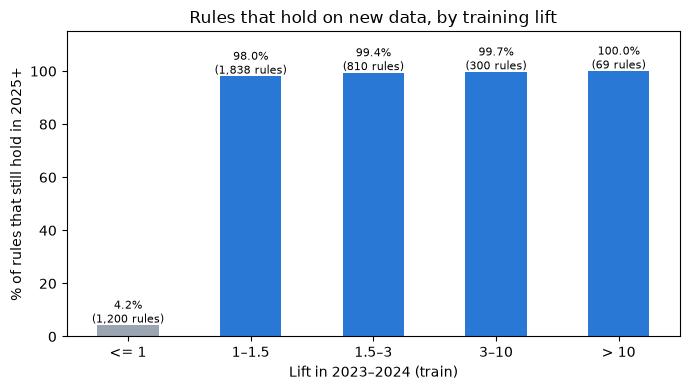

,rules,share_hold
train_lift,,
<= 1,1200,0.042
1–1.5,1838,0.980
1.5–3,810,0.994
3–10,300,0.997
> 10,69,1.000


In [3]:
fail = rules[rules["holds"] == 0]
print(f"rules that fail: {len(fail):,}")
print(f"  test confidence below 10%: {(fail.test_confidence < 0.1).sum()}")
print(f"  test lift 1 or below: {(fail.test_lift <= 1).sum()}  (of these, lift was already <= 1 in training: {((fail.test_lift <= 1) & (fail.train_lift <= 1)).sum()})")

bands = pd.cut(rules["train_lift"], [0, 1, 1.5, 3, 10, 100], labels=["<= 1", "1–1.5", "1.5–3", "3–10", "> 10"])
by_band = rules.groupby(bands, observed=True)["holds"].agg(rules="size", share_hold="mean")
ax = (100 * by_band["share_hold"]).plot(kind="bar", color=[GREY] + [BLUE] * 4, figsize=(7, 4), rot=0)
for i, (n, v) in enumerate(zip(by_band["rules"], by_band["share_hold"])):
    ax.text(i, 100 * v + 1, f"{100 * v:.1f}%\n({n:,} rules)", ha="center", fontsize=8)
ax.set_xlabel("Lift in 2023–2024 (train)")
ax.set_ylabel("% of rules that still hold in 2025+")
ax.set_ylim(0, 115)
ax.set_title("Rules that hold on new data, by training lift")
plt.tight_layout()
plt.savefig(FIGS / "fp_holdout_by_lift.png", dpi=150, bbox_inches="tight")
plt.show()
by_band.round(3)

Nearly all failures are rules that were never a real association. FP-Growth keeps every rule with confidence of at least 10%, so 1,200 of the 4,217 rules had a lift of 1 or below already in training (the items appear together *less* often than by chance, for example a common item like `day=weekday` predicted from a rare one). 1,149 of the 1,191 rules that fail are of this kind. Among the 3,017 rules with lift above 1 in training, 98.6% still hold in 2025+, and 99.5% of the 1,179 rules with lift above 1.5 do. Only 20 rules fail because their confidence fell below 10%.

## The strongest rules, before and after

In [4]:
cols = ["if_items", "then_item", "train_support", "train_confidence", "test_confidence", "train_lift", "test_lift"]
rules[rules.train_lift > 1].sort_values("train_support", ascending=False)[cols].head(10).round(3)

,if_items,then_item,train_support,train_confidence,test_confidence,train_lift,test_lift
3009,dist=0-2mi,day=weekday,0.198,0.671,0.677,1.001,1.000
3010,day=weekday,dist=0-2mi,0.198,0.296,0.285,1.001,1.000
2976,time=midday,day=weekday,0.192,0.675,0.690,1.007,1.020
2977,day=weekday,time=midday,0.192,0.286,0.290,1.007,1.020
2864,time=evening,day=weekday,0.171,0.690,0.691,1.029,1.022
2865,day=weekday,time=evening,0.171,0.256,0.248,1.029,1.022
2676,day=weekend,dist=2-5mi,0.124,0.375,0.368,1.061,1.060
2675,dist=2-5mi,day=weekend,0.124,0.349,0.343,1.061,1.060
1968,day=weekday,time=morning,0.115,0.172,0.175,1.184,1.172
1967,time=morning,day=weekday,0.115,0.794,0.793,1.184,1.172


In [5]:
rules.sort_values("train_lift", ascending=False)[cols].head(10).round(3)

,if_items,then_item,train_support,train_confidence,test_confidence,train_lift,test_lift
0,day=weekday + dist=0-2mi + from=25,to=25,0.002,0.803,0.800,56.110,55.240
1,dist=0-2mi + from=25,to=25,0.003,0.800,0.800,55.940,55.226
2,dist=0-2mi + to=25,from=25,0.003,0.806,0.800,53.575,51.932
3,day=weekday + dist=0-2mi + to=25,from=25,0.002,0.805,0.799,53.475,51.899
4,dist=0-2mi + time=late + to=41,from=41,0.003,0.769,0.785,34.635,32.373
5,day=weekday + dist=0-2mi + time=evening + to=41,from=41,0.002,0.768,0.775,34.579,31.969
6,dist=0-2mi + time=evening + to=41,from=41,0.003,0.758,0.768,34.106,31.674
7,day=weekday + dist=0-2mi + to=41,from=41,0.006,0.743,0.752,33.442,31.042
8,dist=0-2mi + to=41,from=41,0.008,0.734,0.744,33.065,30.705
9,day=weekday + dist=0-2mi + from=41 + time=evening,to=41,0.002,0.730,0.751,32.677,30.523


The most common positive rules and the strongest ones keep their values. Short trips (under 2 miles) that end in Austin start in Austin 80% of the time in both periods (lift 56 and 55), and short evening and late trips that end in Hyde Park start in Hyde Park 76–78% of the time (lift 32–35): these are local trips inside one neighborhood. Long trips that end in the Loop come from O'Hare about half the time in both periods (48% then 52%).

## What this means for the project

- The route patterns from M2 are not a feature of one period: rules with a real association (lift above 1) carry over to 2025–2026 almost unchanged, so the routes we use in the transit-gap score are stable.
- When we report rules, we should keep only those with lift above 1; the minimum confidence of 10% alone lets through rules that are weaker than chance.
- Limits: both periods use 10% samples, so rules near the 0.2% support threshold have some sampling noise; the test is about the same city and the same kinds of trips, not a different city.